# Exercise A
## Time-varying model

## A note on units
Units in GAMERA are mostly in cgs, with several exceptions that are meaningful in the astrophysical context.

    times are in years, except for particle escape time scales
    lengths are in parsecs
    when retrieving SEDs, for convenience the units are
        erg / s / cm2 vs TeV for radiation flux SEDs
        erg / s vs. TeV for luminosity SEDs (i.e. when the distance to the source is not set)
        erg vs. TeV for particle SEDs

    (differential spectra are again in cgs units)
    gas densities are in number densities.

Also, the units of the spectrum will impact the unit of the calculated radiation spectra. For instance, if the unit of the particle spectrum is only differential in energy, i.e. 1/erg, the output radiation spectra will have the unit of a flux if a source distance is specified (see below) or differential photon count per energy and time if not.

On the other hand, if the input unit is differential also in volume, i.e. 1/erg/cm3, then also the output radiation spectrum will be. Therefore, if no distance is specified in this case, a volume photon emissivity will be calculated, i.e. d3N/dEdVdt.

In [1]:
import gappa as gp
import numpy as np
import astropy.units as u
from gammapy.maps import MapAxis
import matplotlib.pyplot as plt


### We will consider a leptonic model for which the magnetic field decreases with time and produce a light-curve

First, define the way the magnetic field changes with time. Try to define a function which would result in noticeable changes over the length of the light-curve.

**Tip**: the cooling times plot we made in tutorial 1 is very useful to understand what values of B will result in noticeable changes on a certain timescale!

In [2]:
def B_field(t,a, t0, B0):
    return (a*(t0/t)*B0).to('G')

and plot it to see

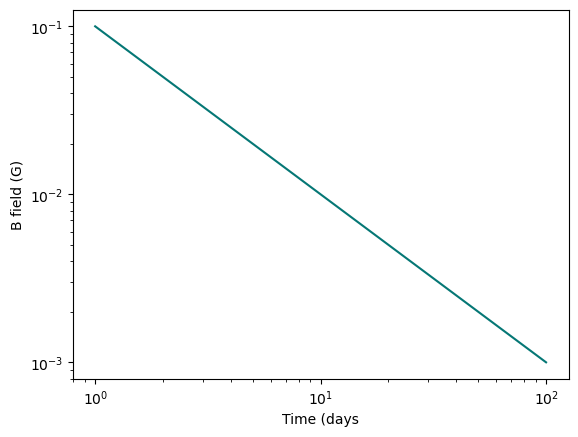

In [3]:
times = np.linspace(1,100,100)*u.day
B = B_field(times,1, 1*u.day, 1e-1*u.G)
plt.loglog(times, B, color='#057775')
plt.xlabel('Time (days')
plt.ylabel('B field (G)')
plt.show()

Prepare the B field object the way GAMERA likes

In [4]:
B_field_lookup = np.array(list(zip(times.to_value('yr'), B.to_value('G'))))


### Define the particle spectrum 

Similar to what we did in the first tutorial, but you can use any shape you want

In [5]:
# A method to create a power-law with a cutoff which we will inject continuously
def define_injected_spectrum(index=2, 
                             E_min=0.1*u.TeV, 
                             E_max=1000*u.TeV, 
                             luminosity=1e36*u.erg/u.s, 
                             E_cut=100*u.TeV,
                             Nbins=50):
    "A power-law with an exponential cutoff"
    energy_electrons = MapAxis.from_energy_bounds(energy_min=E_min, energy_max=E_max, nbin=Nbins)
    exp_cutoff = np.exp(-(energy_electrons.center.to('erg')/E_cut.to('erg')).value)
    power_law = (energy_electrons.center.to_value('erg') ** -index)*exp_cutoff

    # Normalize to total power (this is not really needed but we use it for the plot)
    fu = gp.Utils()
    integral = fu.Integrate(list(zip(energy_electrons.center.to_value('erg'), power_law * energy_electrons.center.to_value('erg'))))
    power_law *= luminosity.to_value('erg s-1') / integral 
    #################################################################################

    
    # Bundle together in the way GAMERA wants
    power_law_spectrum = np.array(list(zip(energy_electrons.center.to_value('erg'), power_law)))

    return power_law_spectrum

Set up the GAMERA classes we will use

In [6]:
fp = gp.Particles()
fp.ToggleQuietMode()


Give it the B field lookup we made earlier

In [7]:
fp.SetBField(B_field_lookup)


Set CMB (or any other) as radiation field

In [8]:
fp.AddThermalTargetPhotons(2.7,0.255*gp.eV_to_erg)


Set minimum time if you are using scales less than years (by default GAMERA sets Tmin=1 yr)

In [9]:
tmin = times[0].to_value('yr')/2
fp.SetTmin(tmin)

Set up the injected spectrum

In [10]:
power_law_spectrum = define_injected_spectrum()
fp.SetCustomInjectionSpectrum(power_law_spectrum)


Calculate electron spectrum at different time intervals by changing fp.SetAge()

In [11]:
electron_seds = []
photon_seds = []
time_intervals=np.linspace(times[1], times[-1],6)
for t in time_intervals:
    t = t.to_value('yr')
    print("Time", t)
    fp.SetAge(t)
    print("B field", fp.GetBField())
    fp.CalculateElectronSpectrum()
    electron_seds.append(np.array(fp.GetParticleSED()))
    print('##')

Time 0.0054757015742642025
B field 0.05
##
Time 0.05913757700205339
B field 0.00462962837027315
##
Time 0.11279945242984257
B field 0.002427184446468526
##
Time 0.16646132785763176
B field 0.0016447368388423007
##
Time 0.22012320328542095
B field 0.0012437810928351653
##
Time 0.2737850787132101
B field 0.0010000000001005773
##


and plot the result

Text(0.5, 1.0, 'Particle SED')

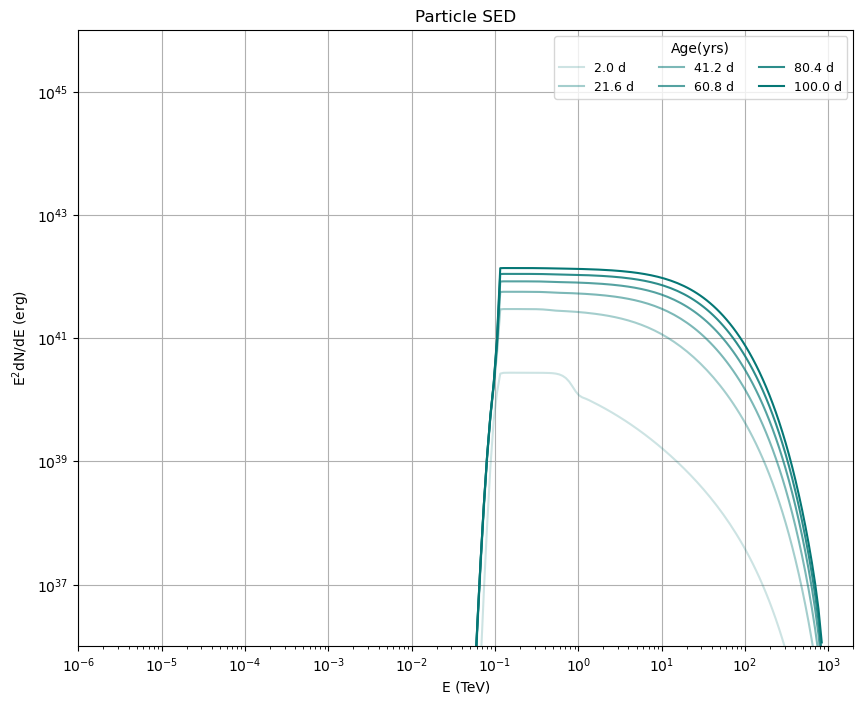

In [12]:
alphas = np.linspace(0.2,1,len(time_intervals))
f = plt.figure(figsize=(10,8))
for s,t,a in list(zip(electron_seds,time_intervals,alphas)):
    plt.loglog(s[:,0],s[:,1],c='#057775',alpha=a,label=str(round(t,1)))
plt.xlabel("E (TeV)")
plt.ylabel("E"+r"$^2$"+"dN/dE (erg)")
plt.grid()
plt.xlim(xmin=1e-6,xmax=2e3)
plt.ylim(ymin=1e36,ymax=1e46)
plt.legend(title="Age(yrs)",ncol=3,fontsize=9)
plt.title("Particle SED")

Now we can make the particles radiate

In [13]:
distance = 1*u.kpc

fr = gp.Radiation()
fr.ToggleQuietMode()
fr.AddThermalTargetPhotons(2.7,0.255*gp.eV_to_erg)
fr.SetDistance(distance.to_value('pc'))
photon_energies = np.logspace(-16,4,200)*u.TeV


Loop over the electron SEDs and the times, set the right B and inject the right spectrum

In [14]:

photon_seds = []

for idx, evolved_electrons in enumerate(electron_seds):
    t = time_intervals[idx]
    B = fp.GetBField(t.to_value('yr'))
    
    fr.SetElectrons(evolved_electrons)
    fr.SetBField(B)

    # compute the spectrum on the points
    fr.CalculateDifferentialPhotonSpectrum(photon_energies.to_value('erg'))

    total_sed = np.asarray(fr.GetTotalSED())
    photon_seds.append(total_sed)

and plot the spectrum

Text(0.5, 1.0, 'Photon SED')

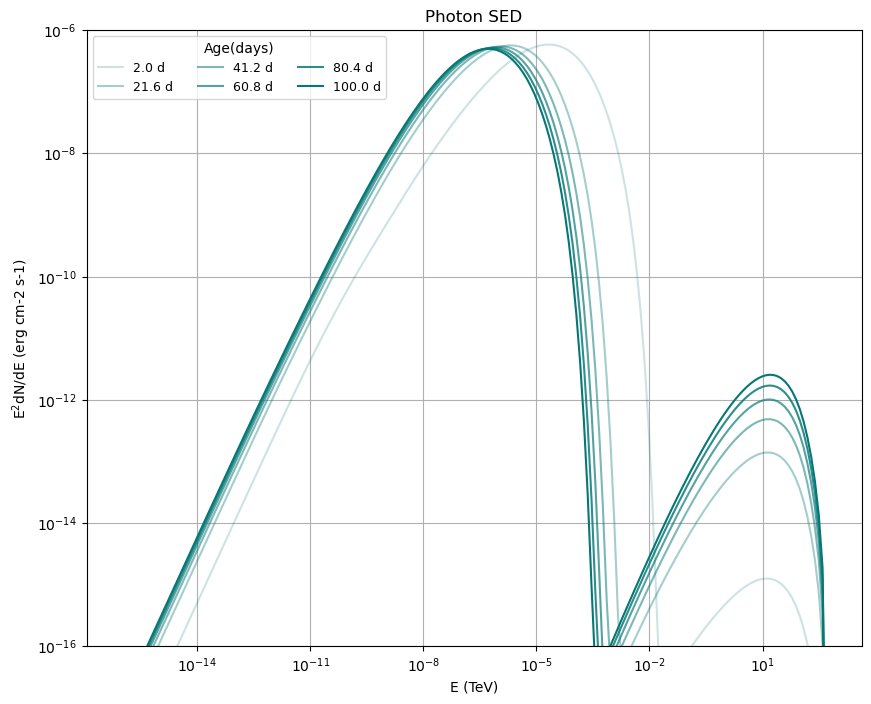

In [15]:

alphas = np.linspace(0.2,1,len(time_intervals))
f = plt.figure(figsize=(10,8))
for s,t,a in list(zip(photon_seds,time_intervals,alphas)):
    plt.loglog(s[:,0],s[:,1],c='#057775',alpha=a,label=str(round(t,1)))
plt.xlabel("E (TeV)")
plt.ylabel("E"+r"$^2$"+"dN/dE (erg cm-2 s-1)")
plt.grid()
#plt.xlim(xmin=1e-6,xmax=2e3)
plt.ylim(ymin=1e-16,ymax=1e-6)
plt.legend(title="Age(days)",ncol=3,fontsize=9)
plt.title("Photon SED")